<a href="https://colab.research.google.com/github/LiamPlower/ML-CampusProject-colab/blob/main/MLProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Campus Data project
Liam Plower

# Data Preparation
Gathering and analysing Information onto excel and applying it to Google colab.


In [ ]:
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Load the Dataset

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/CampusWalkDataset_61026.csv', skiprows=4)

# Drop the specified Unnamed columns if they exist in the dataframe
columns_to_drop = [col for col in df.columns if any(unnamed in col for unnamed in ['Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26'])]
df = df.drop(columns=columns_to_drop, errors='ignore')

# Drop specified rows by index
df = df.drop(index=[66, 67, 68, 134, 135, 136], errors='ignore')

Imported an interactive table that was easier to read, cleared table removing any unused columns using a column drop. Added a filter section to filter between the 1-134 index shows as list 10,25,50 and 100 with pages for each one depeneding on how many you display.

In [ ]:
from google.colab import data_table

# Filter DataFrame to limit row index up to 133
df_limited = df.loc[df.index <= 133]

# Configure and display the DataFrame natively with interactive filtering and row indexes enabled
display(data_table.DataTable(
    df_limited,
    include_index=True,
    num_rows_per_page=10,
    max_columns=25
))

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,...,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,22/09/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,...,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN
1,R26_001,22/09/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,...,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,...,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,...,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,...,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129,R26_027,23/09/2026,L01 MainEntrance,Partly cloudy,17C,Moderate,High,Traffic,Human voices,Trees,...,Many,Some,NaN,Many,Positive wellbeing,Neutral,Mostly calm,A little more connected,Grass,An insect was on my paper
130,R26_027,23/09/2026,L07 CarParkNearSportsCentre,Sunny,19C,Moderate,Moderate,Traffic,Human voices,Trees,...,One or two,Many,NaN,NaN,Neutral,Easy,Mostly calm,No change,Plants,The parking is very full
131,R26_027,23/09/2026,L06 HedgingBehindSportsCentre,Sunny,18C,Moderate,Moderate,Human voices,Traffic,Wind,...,One or two,Some,NaN,NaN,Positive wellbeing,Easy,Mostly calm,A little more connected,Grass,Small apple tree
132,R26_027,23/09/2026,L05 GreenFrontSportsCentre,Windy,16C,Quiet,Low,Traffic,Human voices,Other birds,...,Many,Some,Some,Some,Low wellbeing,Slighly uneasy,Neutral,Less connected,Trees,There are clothes left near a tree


## Data Exploration

In [ ]:
print("\nDataframe shape\n")
print(df.shape)


Dataframe shape

(131, 23)


Prints the number of Rows and Columns I have

## Data Cleaning

In [ ]:
# 1. Check the general structure and find any missing values per column
print(" Missing Values Summary: ")
missing_info = df.isnull().sum()
display(missing_info[missing_info > 0])

# 3. View the final dimensions of our dataset
print(f"\nDataset dimensions after initial cleaning: {df.shape}")

 Missing Values Summary: 


,0
other_sound_type_urban,3
other_sound_type_nature,2
trees_presence,4
native_or_wild_plant_presence,10
ornnamental_or_planted_plant_presence,34
moss_or_lichen_presence,35
most_notable_nature_element,14
other_notes,64



Dataset dimensions after initial cleaning: (131, 23)


Prints missing values summary and uses df.isnull() to find any non value number which then uses.sum() to add them together, which subsequently displays the data. Also prints how mnay columns and rows there are.

### Date Cleaning

In [ ]:
# 1. Clean up any whitespaces around string date entries
df['date'] = df['date'].astype(str).str.strip()

# 2. Convert to datetime using 'mixed' format handling for safety
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# 3. Verify the dates and print how many NaT (errors) resulted
print("=== Date Column Type ===")
print(df['date'].dtypes)
print(f"\nNumber of invalid/missing dates: {df['date'].isna().sum()}")
print("\n=== First 5 Cleaned Dates ===")
display(df['date'].head())

=== Date Column Type ===
datetime64[ns]

Number of invalid/missing dates: 0

=== First 5 Cleaned Dates ===


,date
0,2026-09-22
1,2026-09-22
2,2026-09-22
3,2026-09-22
4,2026-09-22


## Inspection & Encoding

## Sound Level Inspection & Encoding

In [ ]:
# Search for "sound level" in the columns
if 'sound level' in df.columns:
  print(df['sound level'].value_counts(dropna=False))
else:
  print('sound level not found')

sound level
Moderate    58
Quiet       57
Loud        16
NaN         14
Name: count, dtype: int64


Sound level is ordinal categorical data, where the data has a natural order of Quiet < Moderate < Loud.

In [ ]:
# Define Mapping
sound_mapping = {
    'Quiet': 0,
    'Moderate': 1,
    'Loud': 2
}

# Create a new numerical column
df['sound_level_encoded'] = df['sound level'].map(sound_mapping)

# Verify
print("--Mapping Verification--")
print(df[['sound level', 'sound_level_encoded']].drop_duplicates().reset_index(drop=True))

--Mapping Verification--
  sound level  sound_level_encoded
0       Quiet                  0.0
1    Moderate                  1.0
2        Loud                  2.0
3         NaN                  NaN


# Data Correlation

## Heatmap for Data Correlation

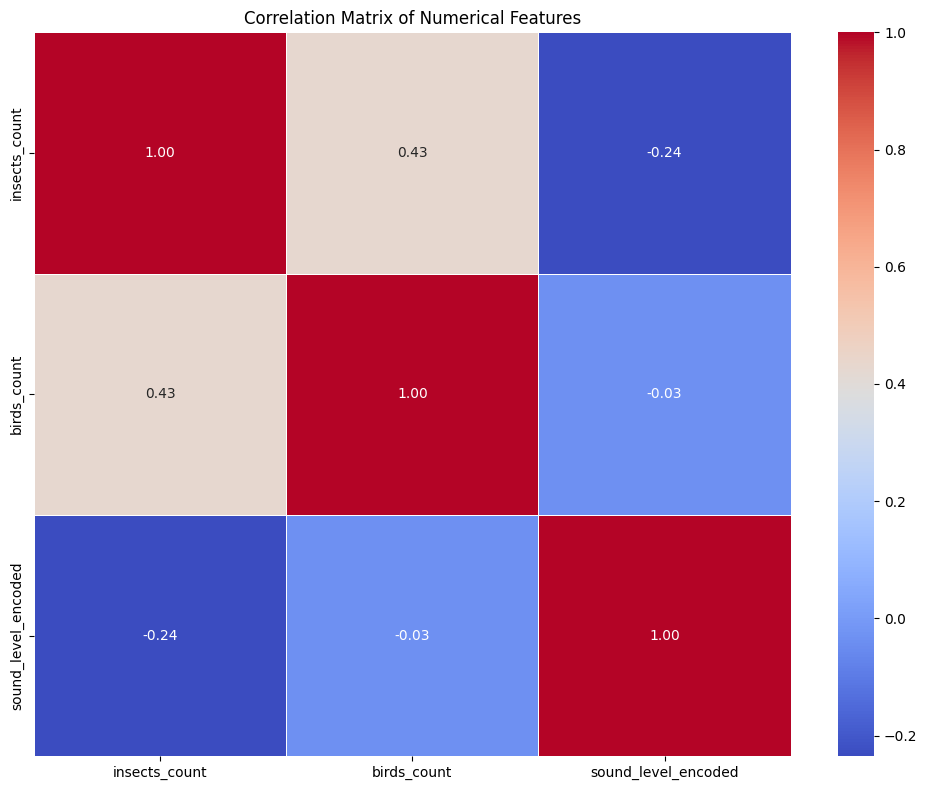

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns for correlation analysis
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Compute the correlation matrix
correlation_matrix = df[numerical_cols].corr()

# Plot the correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()

## Line Graph for Data Correlation

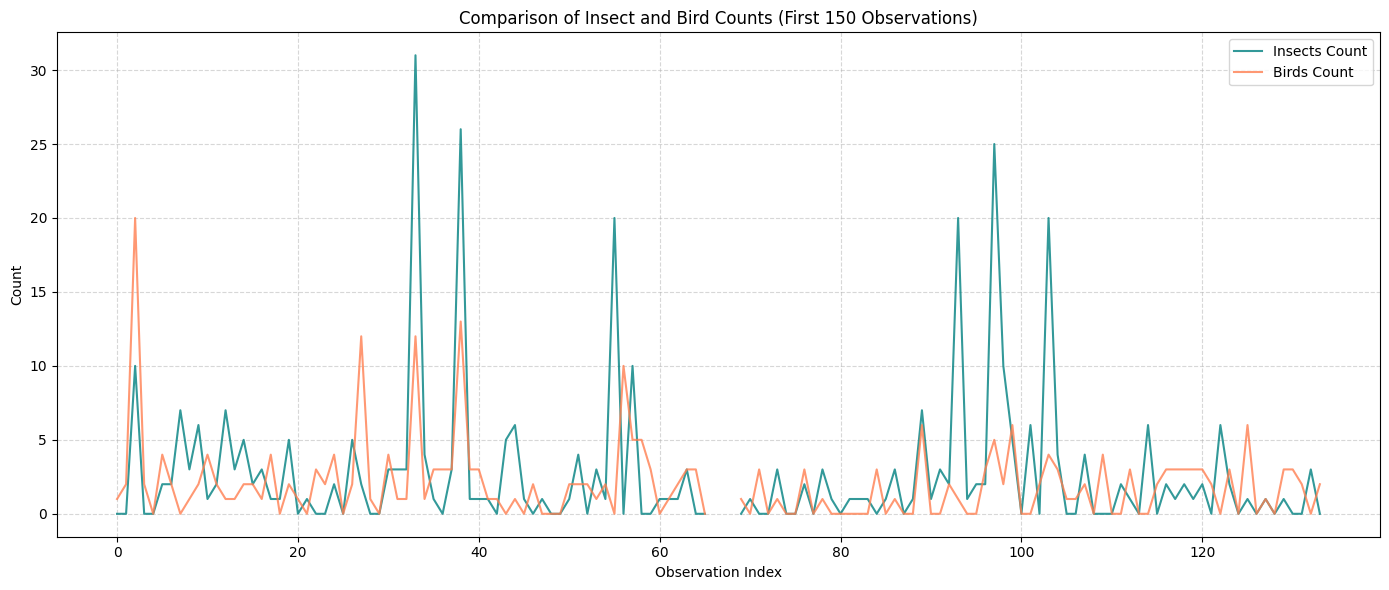

In [ ]:
import matplotlib.pyplot as plt

# Set the figure size
plt.figure(figsize=(14, 6))

# Plot insects_count and birds_count
plt.plot(df.index[:150], df['insects_count'].iloc[:150], label='Insects Count', color='teal', alpha=0.8, linewidth=1.5)
plt.plot(df.index[:150], df['birds_count'].iloc[:150], label='Birds Count', color='coral', alpha=0.8, linewidth=1.5)

# Customize plot details
plt.title('Comparison of Insect and Bird Counts (First 150 Observations)')
plt.xlabel('Observation Index')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()